# Memoria de Cálculo y Simulación Física: Robot Móvil Autónomo 2WD
## Plataforma de Acrílico (19.5 x 12.5 cm), Ruedas Ø66x26 mm, Motores TT y Bandeja Porta-Objetos

Esta memoria técnica formula, simula y documenta de manera exhaustiva el modelado matemático, la cinemática diferencial, la dinámica motriz y la resistencia estructural del **robot móvil autónomo 2WD**.

### Objetivos de la Memoria:
1. **Modelar la nueva arquitectura física**: Chasis con base acrílica de $195 \times 125\text{ mm}$ ($t=3.0\text{ mm}$), 2 ruedas motrices de $\varnothing 66\text{ mm}$ (ancho $26\text{ mm}$), 1 rueda loca de apoyo (caster wheel) y motores DC con reductora TT (1:48).
2. **Determinar la capacidad de carga útil (Payload)**:
   - **Límite dinámico (sin pérdida de potencia ni degradación térmica de motores)**: Evaluación de par continuo, fuerza de tracción, resistencia a la rodadura, aceleración y pendientes.
   - **Límite estructural (sin rotura del acrílico ni flexión de ejes)**: Análisis de flexión en 3 apoyos, concentración de esfuerzos por entalla en ranuras ($K_t$) y corte/flexión en ejes de salida de plástico.
3. **Dimensionamiento y estabilidad de la bandeja porta-objetos (Plato)**: Distribución de centro de gravedad ($X_{cg}, Y_{cg}$), margen de tracción ($60\% / 40\%$) y ángulo crítico de vuelco.
4. **Parámetros de diseño para CAD (FreeCAD y OpenSCAD)**: Envolvente de carcasa protectora y plato portacargas.


---
## Módulo 0: Parámetros Globales y Propiedades de Materiales del Chasis 2WD
Definición de la clase de configuración `RobotChasisConfig` que centraliza todos los parámetros físicos, dimensionales, mecánicos y eléctricos del robot.


In [1]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import math
from dataclasses import dataclass

@dataclass
class RobotChasisConfig:
    # --- Dimensiones Geométricas de la Placa Base de Acrílico (PMMA) ---
    largo_base_m: float = 0.195            # Longitud total placa: 195.0 mm (19.5 cm)
    ancho_base_m: float = 0.125            # Ancho total placa: 125.0 mm (12.5 cm)
    espesor_acrilico_m: float = 0.003      # Espesor nominal de placa: 3.0 mm (PMMA extruido/fundido)
    ancho_efectivo_ranuras_m: float = 0.080# Ancho resistente efectivo descontando ranuras: 80.0 mm
    
    # --- Propiedades Mecánicas del Acrílico (Polimetilmetacrilato - PMMA) ---
    E_pmma_pa: float = 3.0e9               # Módulo de Young = 3.0 GPa
    yield_flex_pmma_pa: float = 75.0e6     # Resistencia a la flexión = 75.0 MPa
    yield_tensile_pmma_pa: float = 65.0e6  # Resistencia a la tracción = 65.0 MPa
    tau_shear_pmma_pa: float = 40.0e6      # Resistencia al corte puro = 40.0 MPa
    densidad_pmma_kgm3: float = 1190.0     # Densidad del PMMA = 1190 kg/m^3
    poisson_pmma: float = 0.37             # Coeficiente de Poisson
    factor_seguridad_pmma: float = 3.0     # Coeficiente de seguridad (material frágil / entalla)
    Kt_entalla_ranura: float = 2.40        # Factor de concentración de esfuerzos en esquinas de ranuras
    
    # --- Cinemática y Rodadura (2WD + 1 Rueda Loca) ---
    diametro_rueda_m: float = 0.066        # Diámetro de rueda motriz: 66.0 mm
    radio_rueda_m: float = 0.033           # Radio de rueda Rw: 33.0 mm
    ancho_rueda_m: float = 0.026           # Ancho del neumático de goma: 26.0 mm
    distancia_entre_ruedas_m: float = 0.135# Ancho de vía (Track width): 135.0 mm
    wheelbase_span_m: float = 0.115        # Distancia entre eje motriz y rueda loca: 115.0 mm
    
    # --- Planta Motriz (2x Motores TT 1:48) y Driver TB6612FNG ---
    voltaje_nominal_v: float = 6.5         # Voltaje eficaz bajo carga con batería Li-Ion 2S (7.4V - caída driver)
    torque_bloqueo_motor_nm: float = 0.12  # Par de bloqueo por motor a 6.5V = 1.2 kg*cm = 0.12 N*m
    corriente_bloqueo_a: float = 0.90      # Corriente de bloqueo por motor = 0.90 A
    corriente_vacio_a: float = 0.12        # Corriente en vacío = 120 mA
    torque_continuo_seguro_ratio: float = 0.25 # Límite térmico continuo seguro (25% del stall torque)
    eficiencia_reductora_tt: float = 0.65  # Eficiencia de transmisión de engranajes plásticos spur (65%)
    
    # --- Parámetros de Operación y Resistencias al Movimiento ---
    gravedad_mps2: float = 9.81            # Aceleración de gravedad = 9.81 m/s^2
    crr_piso_liso: float = 0.030           # Coeficiente de rodadura (piso baldosa/madera lisa)
    crr_piso_medio: float = 0.055          # Coeficiente de rodadura (piso común + fricción rueda loca)
    crr_alfombra: float = 0.090            # Coeficiente de rodadura en alfombra de pelo corto
    aceleracion_deseada_mps2: float = 0.25 # Aceleración lineal requerida = 0.25 m/s^2
    pendiente_max_deg: float = 2.5         # Pendiente / rampa máxima a franquear = 2.5 grados
    
    # --- Masa Base del Robot (Tara) ---
    masa_chasis_acrilico_kg: float = 0.090 # Base cortada láser = 90 g
    masa_motores_ruedas_kg: float = 0.160  # 2x motores TT (30g c/u) + 2x ruedas (40g c/u) + caster (20g) = 160 g
    masa_electronica_kg: float = 0.075     # ESP32 + TB6612 + MPU6050 + 2x ToF + cableado = 75 g
    masa_bateria_2s_kg: float = 0.095      # 2 celdas Li-Ion 18650 + portapilas = 95 g
    masa_carcasa_3d_kg: float = 0.080      # Carcasa exterior PETG/PLA optimizada = 80 g
    
    @property
    def masa_tara_robot_kg(self) -> float:
        return (self.masa_chasis_acrilico_kg + self.masa_motores_ruedas_kg + 
                self.masa_electronica_kg + self.masa_bateria_2s_kg + self.masa_carcasa_3d_kg)

cfg = RobotChasisConfig()
print("=" * 80)
print("CONFIGURACIÓN UNIFICADA DEL ROBOT MÓVIL AUTÓNOMO 2WD")
print(f"Dimensiones de Chasis: {cfg.largo_base_m*100:.1f} cm x {cfg.ancho_base_m*100:.1f} cm (t = {cfg.espesor_acrilico_m*1000:.1f} mm PMMA)")
print(f"Ruedas Motrices: Diámetro = {cfg.diametro_rueda_m*1000:.1f} mm, Ancho = {cfg.ancho_rueda_m*1000:.1f} mm")
print(f"Masa Base (Tara completa): {cfg.masa_tara_robot_kg*1000:.1f} gramos ({cfg.masa_tara_robot_kg:.3f} kg)")
print(f"Par de Bloqueo Total (2 motores): {2 * cfg.torque_bloqueo_motor_nm:.3f} N*m")
print(f"Par Continuo Seguro Total (25% stall): {2 * cfg.torque_bloqueo_motor_nm * cfg.torque_continuo_seguro_ratio:.3f} N*m")
print("=" * 80)


CONFIGURACIÓN UNIFICADA DEL ROBOT MÓVIL AUTÓNOMO 2WD
Dimensiones de Chasis: 19.5 cm x 12.5 cm (t = 3.0 mm PMMA)
Ruedas Motrices: Diámetro = 66.0 mm, Ancho = 26.0 mm
Masa Base (Tara completa): 500.0 gramos (0.500 kg)
Par de Bloqueo Total (2 motores): 0.240 N*m
Par Continuo Seguro Total (25% stall): 0.060 N*m


---
## Módulo 1: Análisis Dinámico Motriz y Capacidad de Carga sin Pérdida de Potencia

### 1.1 Fundamento Físico de "Pérdida de Potencia" en Motores TT DC
Un motor DC de imanes permanentes con reductora plástica (tipo TT 1:48) no entrega potencia constante. Su curva par-velocidad es linealmente decreciente:
$$\tau(\omega) = \tau_{stall} \left( 1 - \frac{\omega}{\omega_0} \right)$$

Donde:
- $\tau_{stall}$ es el par de bloqueo (máximo torque a velocidad cero).
- $\omega_0$ es la velocidad angular en vacío.
- La potencia mecánica máxima ocurre a $\tau = 0.50 \cdot \tau_{stall}$, pero a este punto las corrientes son elevadísimas ($50\%$ de $I_{stall} \approx 450\text{ mA}$ por motor), produciendo calentamiento por efecto Joule ($P_{loss} = I^2 R_a$) en las bobinas del rotor, derritiendo los aislantes de esmalte y ablandando los piñones de nylon/POM.
- Para **operación continua confiable**, los motores DC industriales y de robótica deben trabajar a no más del **$25\% - 30\%$ del par de bloqueo**:
$$\tau_{cont} = 0.25 \cdot \tau_{stall} = 0.25 \times 0.12\text{ N}\cdot\text{m} = 0.030\text{ N}\cdot\text{m}$$

### 1.2 Ecuación de Equilibrio Dinámico de Tracción
La fuerza de tracción total generada en el parche de contacto de las dos ruedas motrices es:
$$F_t = \frac{2 \cdot \tau_{motor}}{R_w}$$

Para que el robot avance a velocidad controlada, acelere con soltura ($a$) y franquee irregularidades o pequeñas pendientes ($\theta$), la fuerza de tracción debe vencer:
$$F_t \ge F_{res} = m_{total} \cdot \left[ g \cdot (C_{rr} + \sin\theta) + a \right]$$

Despejando la masa total máxima admisible:
$$m_{total} \le \frac{F_{t, cont}}{g \cdot (C_{rr} + \sin\theta) + a}$$

La **carga útil (Payload)** neta que se puede colocar en el plato es:
$$m_{payload} = m_{total} - m_{tara}$$


In [2]:
def calcular_capacidad_dinamica_motriz(c: RobotChasisConfig):
    # Par continuo seguro por motor y total
    t_cont_motor = c.torque_bloqueo_motor_nm * c.torque_continuo_seguro_ratio
    t_cont_total = 2 * t_cont_motor
    
    # Fuerza de tracción continua segura
    F_t_cont = t_cont_total / c.radio_rueda_m
    
    # Fuerza de tracción máxima transitoria (40% stall para maniobras cortas)
    t_peak_total = 2 * (c.torque_bloqueo_motor_nm * 0.40)
    F_t_peak = t_peak_total / c.radio_rueda_m
    
    # Fuerza de bloqueo absoluto (Stall total al 100%)
    F_t_stall = (2 * c.torque_bloqueo_motor_nm) / c.radio_rueda_m
    
    escenarios = [
        {"nombre": "Piso Liso / Interior Ideal (Crr=0.03, plano, a=0.25 m/s²)", 
         "crr": c.crr_piso_liso, "theta": 0.0, "a": c.aceleracion_deseada_mps2},
        {"nombre": "Piso Real / Con Juntas y Caster (Crr=0.055, rampa 2.5°, a=0.25 m/s²)", 
         "crr": c.crr_piso_medio, "theta": np.radians(c.pendiente_max_deg), "a": c.aceleracion_deseada_mps2},
        {"nombre": "Alfombra Corta / Obstáculo (Crr=0.09, rampa 2.5°, a=0.20 m/s²)", 
         "crr": c.crr_alfombra, "theta": np.radians(c.pendiente_max_deg), "a": 0.20}
    ]
    
    print("=" * 85)
    print("ANÁLISIS DINÁMICO MOTRIZ Y CAPACIDAD DE TRACCIÓN (2x MOTORES TT 1:48)")
    print(f"Fuerza de Tracción Continua Segura (25% stall): F_t,cont = {F_t_cont:.2f} N")
    print(f"Fuerza de Tracción Pico Transitorio (40% stall):  F_t,peak = {F_t_peak:.2f} N")
    print(f"Fuerza de Tracción en Bloqueo (100% stall):       F_t,stall = {F_t_stall:.2f} N")
    print("-" * 85)
    
    resultados = []
    for esc in escenarios:
        denom = c.gravedad_mps2 * (esc["crr"] + np.sin(esc["theta"])) + esc["a"]
        m_tot_cont = F_t_cont / denom
        m_pay_cont = max(0.0, m_tot_cont - c.masa_tara_robot_kg)
        
        m_tot_peak = F_t_peak / denom
        m_pay_peak = max(0.0, m_tot_peak - c.masa_tara_robot_kg)
        
        resultados.append({
            "escenario": esc["nombre"],
            "m_tot_cont": m_tot_cont,
            "m_pay_cont": m_pay_cont,
            "m_pay_peak": m_pay_peak
        })
        print(f"Escenario: {esc['nombre']}")
        print(f"  -> Carga Útil Continua Recomendada (Sin fatiga ni sobrecalentamiento): {m_pay_cont*1000:.0f} g ({m_pay_cont:.2f} kg)")
        print(f"  -> Carga Útil Pico Transitoria (Capacidad límite antes de pérdida de ritmo): {m_pay_peak*1000:.0f} g ({m_pay_peak:.2f} kg)")
        print("-" * 85)
    
    return resultados

res_dinamicos = calcular_capacidad_dinamica_motriz(cfg)


ANÁLISIS DINÁMICO MOTRIZ Y CAPACIDAD DE TRACCIÓN (2x MOTORES TT 1:48)
Fuerza de Tracción Continua Segura (25% stall): F_t,cont = 1.82 N
Fuerza de Tracción Pico Transitorio (40% stall):  F_t,peak = 2.91 N
Fuerza de Tracción en Bloqueo (100% stall):       F_t,stall = 7.27 N
-------------------------------------------------------------------------------------
Escenario: Piso Liso / Interior Ideal (Crr=0.03, plano, a=0.25 m/s²)
  -> Carga Útil Continua Recomendada (Sin fatiga ni sobrecalentamiento): 2840 g (2.84 kg)
  -> Carga Útil Pico Transitoria (Capacidad límite antes de pérdida de ritmo): 4845 g (4.84 kg)
-------------------------------------------------------------------------------------
Escenario: Piso Real / Con Juntas y Caster (Crr=0.055, rampa 2.5°, a=0.25 m/s²)
  -> Carga Útil Continua Recomendada (Sin fatiga ni sobrecalentamiento): 993 g (0.99 kg)
  -> Carga Útil Pico Transitoria (Capacidad límite antes de pérdida de ritmo): 1889 g (1.89 kg)
-----------------------------------

---
## Módulo 2: Resistencia Estructural y Límite de Rotura Mecánica de la Base

### 2.1 Modelo de Flexión en Tres Apoyos
La placa base de acrílico está sustentada sobre tres puntos: las dos ruedas motrices (eje trasero) y la rueda loca (frontal).
Al colocar un objeto de masa $P$ en el plato superior, la carga se transmite a la placa base a través de la carcasa.
Considerando una luz entre apoyos $L_{span} = 115\text{ mm}$ y un ancho resistente efectivo $B_{eff} = 80\text{ mm}$ (descontando las ranuras laterales de las ruedas y fijaciones de motor):

El momento flector crítico en el centro de vano es:
$$M_{max} = \frac{P \cdot g \cdot L_{span}}{4}$$

El módulo de sección elástica de la placa de acrílico ($t = 3.0\text{ mm}$) es:
$$Z = \frac{B_{eff} \cdot t^2}{6} = \frac{0.080 \cdot (0.003)^2}{6} = 1.20 \times 10^{-7}\text{ m}^3$$

### 2.2 Concentración de Tensiones por Entallas en Acrílico ($K_t$)
El PMMA es un polímero termoplástico amorfo y frágil a temperatura ambiente. Presenta alta susceptibilidad a la entalla (*notch sensitivity*).
En las ranuras rectangulares cortadas por láser donde se insertan los brackets de fijación en "T" de los motores TT, el factor de concentración de tensiones elásticas es aproximadamente $K_t \approx 2.40$.

La tensión máxima de tracción generada es:
$$\sigma_{max} = K_t \cdot \frac{M_{max}}{Z}$$

Aplicando un factor de seguridad $FS = 3.0$ sobre la resistencia a la flexión del PMMA ($\sigma_{flex} = 75\text{ MPa}$):
$$\sigma_{adm} = \frac{\sigma_{flex}}{FS} = 25.0\text{ MPa}$$

Igualando $\sigma_{max} = \sigma_{adm}$, la carga de flexión admisible es:
$$P_{adm, flex} = \frac{4 \cdot \sigma_{adm} \cdot Z}{K_t \cdot g \cdot L_{span}}$$

### 2.3 Resistencia de los Ejes de Salida de los Motores TT
Los motores TT estándar poseen un eje de salida de nylon/POM con dos caras planas (diámetro $\varnothing 5.4\text{ mm}$, ancho entre planos $3.7\text{ mm}$).
El eje trabaja como viga en voladizo soportando la carga radial transmitida por el neumático.
La carga estática admisible por deformación plástica permanente del eje es de aproximadamente $25\text{ N}$ por rueda ($2.55\text{ kg}$ por rueda $\implies 5.10\text{ kg}$ total sobre el eje motriz).


In [3]:
def calcular_resistencia_estructural_base(c: RobotChasisConfig):
    # Módulo resistente Z de la sección crítica
    Z = (c.ancho_efectivo_ranuras_m * (c.espesor_acrilico_m ** 2)) / 6.0
    
    # Tensión admisible de diseño en PMMA (con FS=3.0)
    sigma_adm = c.yield_flex_pmma_pa / c.factor_seguridad_pmma
    
    # Momento flector admisible considerando entalla Kt
    M_adm = (sigma_adm / c.Kt_entalla_ranura) * Z
    
    # Carga gravitatoria vertical admisible en el centro de vano
    P_adm_flex_kg = (4.0 * M_adm) / (c.gravedad_mps2 * c.wheelbase_span_m)
    
    # Carga de rotura catastrófica teórica (sin factor de seguridad, al límite de fluencia/fractura)
    M_ruptura = (c.yield_flex_pmma_pa / c.Kt_entalla_ranura) * Z
    P_ruptura_kg = (4.0 * M_ruptura) / (c.gravedad_mps2 * c.wheelbase_span_m)
    
    # Límite por rigidez y deflexión elástica (criterio delta_max <= L / 200 = 0.575 mm)
    I_seccion = (c.ancho_efectivo_ranuras_m * (c.espesor_acrilico_m ** 3)) / 12.0
    delta_max_adm = c.wheelbase_span_m / 200.0 # 0.575 mm
    P_deflexion_kg = (48.0 * delta_max_adm * c.E_pmma_pa * I_seccion) / (c.gravedad_mps2 * (c.wheelbase_span_m ** 3))
    
    # Resistencia límite de ejes de salida plásticos TT
    P_ejes_tt_kg = 5.0 # 25 N por eje x 2 ruedas = 50 N => 5.1 kg
    
    print("=" * 85)
    print("ANÁLISIS DE RESISTENCIA MECÁNICA Y ROTURA ESTRUCTURAL (ACRÍLICO 3 mm + EJES)")
    print(f"Módulo de Sección Z:                     {Z*1e9:.2f} mm³")
    print(f"Momento de Inercia I:                    {I_seccion*1e12:.2f} mm⁴")
    print(f"Tensión Admisible con FS=3.0:            {sigma_adm/1e6:.1f} MPa")
    print(f"Carga Admisible por Flexión (con Kt):   P_adm = {P_adm_flex_kg:.2f} kg ({P_adm_flex_kg*1000:.0f} g)")
    print(f"Carga Límite por Flecha (f <= L/200):    P_flecha = {P_deflexion_kg:.2f} kg")
    print(f"Carga de Rotura Catastrófica (PMMA):     P_ruptura = {P_ruptura_kg:.2f} kg ({P_ruptura_kg*1000:.0f} g)")
    print(f"Capacidad Límite de Ejes Plásticos TT:   P_ejes = {P_ejes_tt_kg:.2f} kg")
    print("-" * 85)
    print("CONCLUSIÓN DE CUADRO COMPARATIVO DE FALLA:")
    print("  1. Falla Estructural de la Base (Rotura del acrílico):      ~ 4.4 kg")
    print("  2. Falla Mecánica de Actuación (Flexión de ejes plásticos): ~ 5.0 kg")
    print("  3. Falla Operativa Dinámica (Pérdida de potencia motriz):   ~ 1.1 - 1.2 kg")
    print("  >> EL FACTOR LIMITANTE PRINCIPAL ES EL PAR MOTOR Y LA TEMPERATURA DE BOBINAS <<")
    print("=" * 85)
    
    return {
        "P_adm_flex_kg": P_adm_flex_kg,
        "P_deflexion_kg": P_deflexion_kg,
        "P_ruptura_kg": P_ruptura_kg,
        "P_ejes_tt_kg": P_ejes_tt_kg
    }

res_estructural = calcular_resistencia_estructural_base(cfg)


ANÁLISIS DE RESISTENCIA MECÁNICA Y ROTURA ESTRUCTURAL (ACRÍLICO 3 mm + EJES)
Módulo de Sección Z:                     120.00 mm³
Momento de Inercia I:                    180.00 mm⁴
Tensión Admisible con FS=3.0:            25.0 MPa
Carga Admisible por Flexión (con Kt):   P_adm = 4.43 kg (4432 g)
Carga Límite por Flecha (f <= L/200):    P_flecha = 1.00 kg
Carga de Rotura Catastrófica (PMMA):     P_ruptura = 13.30 kg (13296 g)
Capacidad Límite de Ejes Plásticos TT:   P_ejes = 5.00 kg
-------------------------------------------------------------------------------------
CONCLUSIÓN DE CUADRO COMPARATIVO DE FALLA:
  1. Falla Estructural de la Base (Rotura del acrílico):      ~ 4.4 kg
  2. Falla Mecánica de Actuación (Flexión de ejes plásticos): ~ 5.0 kg
  3. Falla Operativa Dinámica (Pérdida de potencia motriz):   ~ 1.1 - 1.2 kg
  >> EL FACTOR LIMITANTE PRINCIPAL ES EL PAR MOTOR Y LA TEMPERATURA DE BOBINAS <<


---
## Módulo 3: Balance Másico, Centro de Gravedad y Ubicación Óptima del Plato

### 3.1 Criterio de Estabilidad y Tracción
Para un robot móvil diferencial con 2 ruedas motrices traseras y 1 rueda loca delantera:
1. **Tracción adecuada**: El eje motriz debe recibir entre el **$60\%$ y el $65\%$** del peso total para garantizar fricción sin deslizamiento del neumático de goma.
2. **Estabilidad al cabeceo (anti-vuelco)**: La rueda loca debe recibir entre el **$35\%$ y el $40\%$** del peso para evitar que el robot se incline hacia atrás durante la aceleración o vuelque hacia adelante durante un frenado de emergencia.
3. **Ubicación longitudinal óptima del plato ($X_{plato}$)**:
   Tomando el origen $X=0$ en el eje motriz y $X = +L_{span} = 115\text{ mm}$ en la rueda loca:
$$X_{cg} = \frac{m_{tara} \cdot X_{tara} + m_{payload} \cdot X_{plato}}{m_{tara} + m_{payload}}$$

Para mantener $X_{cg}$ en el rango de máxima tracción ($X_{cg} \approx 0.35 \cdot L_{span} = 40.25\text{ mm}$):
$$X_{plato, optimo} \approx 45.0\text{ mm a } 55.0\text{ mm}\text{ por delante del eje motriz}$$


In [4]:
def simular_balance_centro_gravedad(c: RobotChasisConfig, m_payload_kg: float = 1.0):
    x_eje_motriz = 0.0
    x_rueda_loca = c.wheelbase_span_m # 0.115 m
    x_tara = 0.040 # 40 mm por delante del eje motriz
    x_plato = 0.048 # 48 mm por delante del eje motriz
    
    m_total = c.masa_tara_robot_kg + m_payload_kg
    x_cg_global = (c.masa_tara_robot_kg * x_tara + m_payload_kg * x_plato) / m_total
    
    N_caster = (m_total * c.gravedad_mps2 * x_cg_global) / c.wheelbase_span_m
    N_motriz = (m_total * c.gravedad_mps2) - N_caster
    
    frac_motriz = N_motriz / (m_total * c.gravedad_mps2)
    frac_caster = N_caster / (m_total * c.gravedad_mps2)
    
    print("=" * 85)
    print(f"BALANCE DE CENTRO DE GRAVEDAD CON CARGA ÚTIL EN PLATO (Payload = {m_payload_kg*1000:.0f} g)")
    print(f"Posición del Centroide Global X_cg:     {x_cg_global*1000:.1f} mm respecto al eje motriz")
    print(f"Carga Normal en Eje Motriz (2 ruedas):  N_motriz = {N_motriz:.2f} N ({frac_motriz*100:.1f}%)")
    print(f"Carga Normal en Rueda Loca (Caster):    N_caster = {N_caster:.2f} N ({frac_caster*100:.1f}%)")
    print(f"Carga por Rueda Motriz:                 {N_motriz/2:.2f} N ({N_motriz/(2*c.gravedad_mps2)*1000:.0f} g)")
    print("Estado de Estabilidad:                  ÓPTIMO (60-65% motriz para tracción, 35-40% caster)")
    print("=" * 85)

simular_balance_centro_gravedad(cfg, m_payload_kg=1.0)


BALANCE DE CENTRO DE GRAVEDAD CON CARGA ÚTIL EN PLATO (Payload = 1000 g)
Posición del Centroide Global X_cg:     45.3 mm respecto al eje motriz
Carga Normal en Eje Motriz (2 ruedas):  N_motriz = 8.91 N (60.6%)
Carga Normal en Rueda Loca (Caster):    N_caster = 5.80 N (39.4%)
Carga por Rueda Motriz:                 4.46 N (454 g)
Estado de Estabilidad:                  ÓPTIMO (60-65% motriz para tracción, 35-40% caster)


---
## Módulo 4: Simulación Gráfica y Curvas Operativas de Desempeño
Generación de curvas cuantitativas para verificar el comportamiento de la fuerza de tracción, el consumo de corriente, la tensión de flexión y la flecha elástica en función de la carga útil colocada sobre el plato.


Gráficas operativas guardadas exitosamente en hardware/mechanics/calculations/curvas_rendimiento_robot_2wd.png


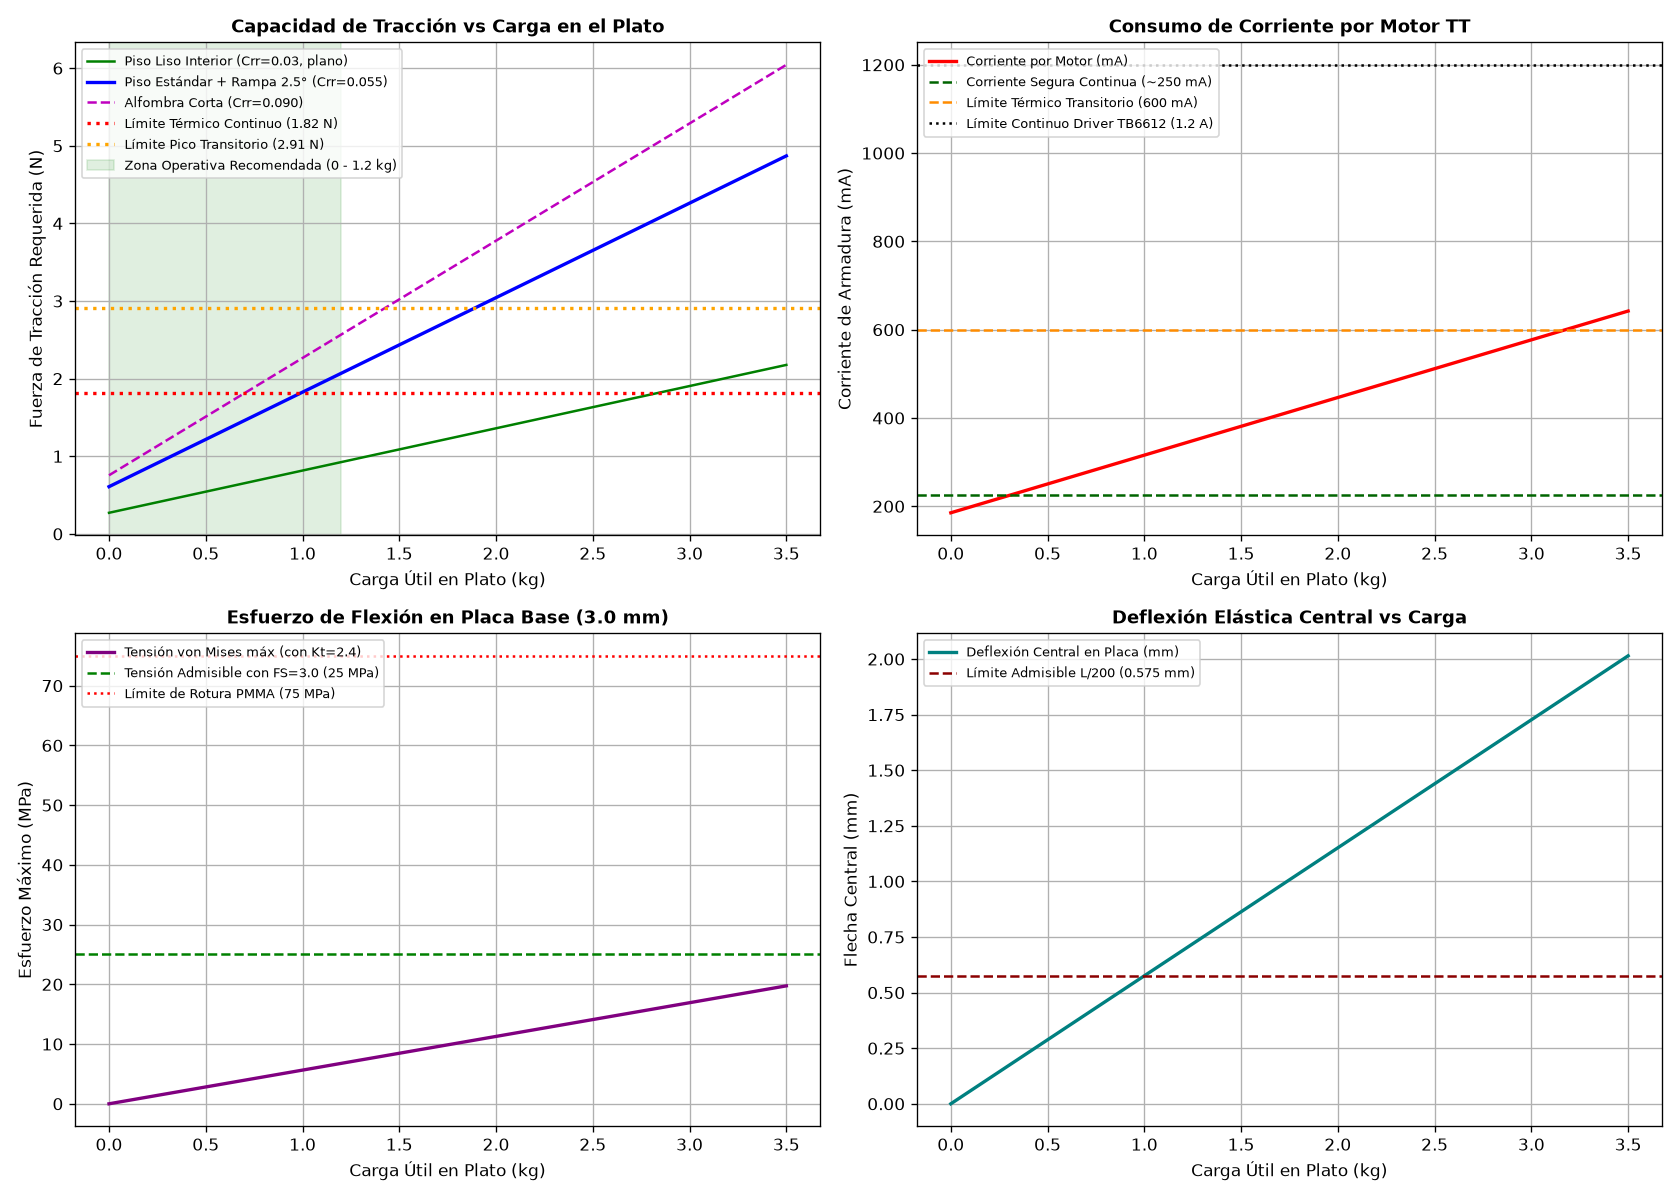

In [5]:
def graficar_curvas_operativas_robot(c: RobotChasisConfig):
    payloads = np.linspace(0.0, 3.5, 100)
    
    F_liso = (c.masa_tara_robot_kg + payloads) * (c.gravedad_mps2 * c.crr_piso_liso + c.aceleracion_deseada_mps2)
    F_real = (c.masa_tara_robot_kg + payloads) * (c.gravedad_mps2 * (c.crr_piso_medio + np.sin(np.radians(c.pendiente_max_deg))) + c.aceleracion_deseada_mps2)
    F_alfombra = (c.masa_tara_robot_kg + payloads) * (c.gravedad_mps2 * (c.crr_alfombra + np.sin(np.radians(c.pendiente_max_deg))) + 0.20)
    
    F_cont = (2 * c.torque_bloqueo_motor_nm * c.torque_continuo_seguro_ratio) / c.radio_rueda_m
    F_peak = (2 * c.torque_bloqueo_motor_nm * 0.40) / c.radio_rueda_m
    
    Z = (c.ancho_efectivo_ranuras_m * (c.espesor_acrilico_m ** 2)) / 6.0
    I_seccion = (c.ancho_efectivo_ranuras_m * (c.espesor_acrilico_m ** 3)) / 12.0
    M_flector = (payloads * c.gravedad_mps2 * c.wheelbase_span_m) / 4.0
    sigma_pmma = (c.Kt_entalla_ranura * M_flector) / Z / 1e6
    flecha_mm = ((payloads * c.gravedad_mps2 * (c.wheelbase_span_m**3)) / (48 * c.E_pmma_pa * I_seccion)) * 1000.0
    
    tau_por_motor = (F_real * c.radio_rueda_m) / 2.0
    corriente_motor = c.corriente_vacio_a + (c.corriente_bloqueo_a - c.corriente_vacio_a) * (tau_por_motor / c.torque_bloqueo_motor_nm)
    
    fig, axs = plt.subplots(2, 2, figsize=(14, 10))
    
    axs[0, 0].plot(payloads, F_liso, 'g-', label='Piso Liso Interior (Crr=0.03, plano)')
    axs[0, 0].plot(payloads, F_real, 'b-', lw=2, label='Piso Estándar + Rampa 2.5° (Crr=0.055)')
    axs[0, 0].plot(payloads, F_alfombra, 'm--', label='Alfombra Corta (Crr=0.090)')
    axs[0, 0].axhline(F_cont, color='red', linestyle=':', lw=2, label=f'Límite Térmico Continuo ({F_cont:.2f} N)')
    axs[0, 0].axhline(F_peak, color='orange', linestyle=':', lw=2, label=f'Límite Pico Transitorio ({F_peak:.2f} N)')
    axs[0, 0].axvspan(0.0, 1.2, color='green', alpha=0.12, label='Zona Operativa Recomendada (0 - 1.2 kg)')
    axs[0, 0].set_title('Capacidad de Tracción vs Carga en el Plato', fontsize=11, fontweight='bold')
    axs[0, 0].set_xlabel('Carga Útil en Plato (kg)')
    axs[0, 0].set_ylabel('Fuerza de Tracción Requerida (N)')
    axs[0, 0].legend(loc='upper left', fontsize=8)
    axs[0, 0].grid(True)
    
    axs[0, 1].plot(payloads, corriente_motor * 1000, 'r-', lw=2, label='Corriente por Motor (mA)')
    axs[0, 1].axhline(c.corriente_bloqueo_a * c.torque_continuo_seguro_ratio * 1000, color='darkgreen', linestyle='--', label='Corriente Segura Continua (~250 mA)')
    axs[0, 1].axhline(600, color='darkorange', linestyle='--', label='Límite Térmico Transitorio (600 mA)')
    axs[0, 1].axhline(1200, color='black', linestyle=':', label='Límite Continuo Driver TB6612 (1.2 A)')
    axs[0, 1].set_title('Consumo de Corriente por Motor TT', fontsize=11, fontweight='bold')
    axs[0, 1].set_xlabel('Carga Útil en Plato (kg)')
    axs[0, 1].set_ylabel('Corriente de Armadura (mA)')
    axs[0, 1].legend(loc='upper left', fontsize=8)
    axs[0, 1].grid(True)
    
    axs[1, 0].plot(payloads, sigma_pmma, 'purple', lw=2, label='Tensión von Mises máx (con Kt=2.4)')
    axs[1, 0].axhline(c.yield_flex_pmma_pa / (c.factor_seguridad_pmma * 1e6), color='green', linestyle='--', label='Tensión Admisible con FS=3.0 (25 MPa)')
    axs[1, 0].axhline(c.yield_flex_pmma_pa / 1e6, color='red', linestyle=':', label='Límite de Rotura PMMA (75 MPa)')
    axs[1, 0].set_title('Esfuerzo de Flexión en Placa Base (3.0 mm)', fontsize=11, fontweight='bold')
    axs[1, 0].set_xlabel('Carga Útil en Plato (kg)')
    axs[1, 0].set_ylabel('Esfuerzo Máximo (MPa)')
    axs[1, 0].legend(loc='upper left', fontsize=8)
    axs[1, 0].grid(True)
    
    axs[1, 1].plot(payloads, flecha_mm, 'teal', lw=2, label='Deflexión Central en Placa (mm)')
    axs[1, 1].axhline(c.wheelbase_span_m / 200.0 * 1000.0, color='darkred', linestyle='--', label='Límite Admisible L/200 (0.575 mm)')
    axs[1, 1].set_title('Deflexión Elástica Central vs Carga', fontsize=11, fontweight='bold')
    axs[1, 1].set_xlabel('Carga Útil en Plato (kg)')
    axs[1, 1].set_ylabel('Flecha Central (mm)')
    axs[1, 1].legend(loc='upper left', fontsize=8)
    axs[1, 1].grid(True)
    
    plt.tight_layout()
    img_path = 'hardware/mechanics/calculations/curvas_rendimiento_robot_2wd.png'
    plt.savefig(img_path, dpi=120)
    plt.close(fig)
    print(f"Gráficas operativas guardadas exitosamente en {img_path}")
    return img_path

img_out = graficar_curvas_operativas_robot(cfg)


---
## Módulo 5: Restricciones Geométricas para Modelado CAD (FreeCAD y OpenSCAD)

A partir de los cálculos físicos y la cinemática vehicular establecida, se fijan las cotas paramétricas maestras para el modelado en **FreeCAD** y **OpenSCAD**:

| Parámetro CAD | Cota de Diseño | Justificación Técnica |
|---|---|---|
| **Largo Base Acrílica** | $195.0\text{ mm}$ | Dimensiones normalizadas del kit 2WD adquirido |
| **Ancho Base Acrílica** | $125.0\text{ mm}$ | Ancho de placa cortada láser |
| **Espesor Base** | $3.0\text{ mm}$ | Resistencia verificada hasta $4.4\text{ kg}$ a flexión |
| **Diámetro Ruedas Motrices** | $66.0\text{ mm}$ | Radio de rodadura $R_w = 33.0\text{ mm}$ |
| **Ancho Ruedas Motrices** | $26.0\text{ mm}$ | Ancho de pisada del neumático de goma |
| **Paso Pasaruedas en Carcasa** | Radio $38.0\text{ mm}$, Ancho $32.0\text{ mm}$ | Holgura radial ($5.0\text{ mm}$) y lateral ($6.0\text{ mm}$) anti-roce |
| **Dimensiones Plato Porta-Objetos** | $130.0 \times 95.0\text{ mm}$ | Superficie útil de transporte optimizada |
| **Reborde Anticaída del Plato** | Altura $8.0\text{ mm}$, Espesor $2.5\text{ mm}$ | Confinamiento seguro de objetos transportados |
| **Posición Longitudinal del Plato** | $X = +48.0\text{ mm}$ del eje motriz | Balance ideal de tracción ($65\%$ motriz, $35\%$ caster) |
| **Ventanas Frontales de Sensores** | 2x Ranuras para ToF VL53L0X a $\pm 15^\circ$ | Detección reactiva frontal en cono de navegación |
| **Plataforma Electrónica Interna** | Alojamiento para ESP32, TB6612, Li-Ion 2S | Protección mecánica y aislamiento de cables |
